## Instalación de dependencias

In [12]:
# 1. Instalación e importación de dependencias 
import random 
import numpy as np 
import matplotlib.pyplot as plt

In [13]:
# Fijar semilla aleatoria para asegurabilidad y reproducibilidad en laboratorio 
SEED = 42 
random.seed(SEED) 
np.random.seed(SEED)

In [14]:
# 2. Configuración del problema y espacio de búsqueda 
ALFABETO = "ABCDEFGHIJKLMNÑOPQRSTUVWXYZ0123456789 "
FRASE_OBJETIVO = "IA EVOLUTIVA 2026" 
LONGITUD_FRASE = len(FRASE_OBJETIVO)
print(f"Target: '{FRASE_OBJETIVO}' | Longitud (N): {LONGITUD_FRASE} | Alfabeto (|A|): {len(ALFABETO)}")

Target: 'IA EVOLUTIVA 2026' | Longitud (N): 17 | Alfabeto (|A|): 38


In [15]:
# 3. Funciones modulares del algoritmo genético 
def crear_individuo(longitud): 
    return ''.join(random.choice(ALFABETO) for _ in range(longitud)) 

def crear_poblacion(tamano, longitud): 
    return [crear_individuo(longitud) for _ in range(tamano)] 

def evaluar_fitness(individuo, objetivo): 
    return sum(1 for a, b in zip(individuo, objetivo) if a == b) 

def seleccion_torneo(poblacion, fitnesses, k=3): 
    seleccionados = random.sample(list(zip(poblacion, fitnesses)), k) 
    seleccionados.sort(key=lambda x: x[1], reverse=True) 
    return seleccionados[0][0] 

def cruce_un_punto(padre1, padre2, prob_cruce=0.85): 
    if random.random() < prob_cruce: 
        punto = random.randint(1, len(padre1) - 1) 
        return padre1[:punto] + padre2[punto:], padre2[:punto] + padre1[punto:] 
    return padre1, padre2 

def mutacion(individuo, prob_mutacion=0.01): 
    return ''.join(random.choice(ALFABETO) if random.random() < prob_mutacion else c for c in individuo)

In [16]:
# 4. Bucle evolutivo principal con Elitismo 
def ejecutar_ag(objetivo, tam_poblacion=150, max_generaciones=200, prob_cruce=0.85, prob_mutacion=0.01, k_torneo=3): 
    longitud = len(objetivo) 
    poblacion = crear_poblacion(tam_poblacion, longitud) 
    historial_max, historial_avg = [], [] 
    for gen in range(1, max_generaciones + 1): 
        fitnesses = [evaluar_fitness(ind, objetivo) for ind in poblacion] 
        max_fit = max(fitnesses) 
        avg_fit = sum(fitnesses) / tam_poblacion 
        mejor_ind = poblacion[fitnesses.index(max_fit)] 
        historial_max.append(max_fit) 
        historial_avg.append(avg_fit) 
        if gen == 1 or gen % 20 == 0 or max_fit == longitud: 
            print(f"Gen {gen:03d} | Fit Máx: {max_fit:02d}/{longitud} | Promedio: {avg_fit:.2f} | Mejor: '{mejor_ind}'") 
        if max_fit == longitud: 
            print(f"n¡CONVERGENCIA ALCANZADA en la Generación {gen}!") 
            break 
    # Elitismo: Preservar al mejor individuo de la generación 
    nueva_poblacion = [mejor_ind] 
    while len(nueva_poblacion) < tam_poblacion: 
        p1 = seleccion_torneo(poblacion, fitnesses, k_torneo) 
        p2 = seleccion_torneo(poblacion, fitnesses, k_torneo) 
        h1, h2 = cruce_un_punto(p1, p2, prob_cruce) 
        nueva_poblacion.append(mutacion(h1, prob_mutacion)) 
        if len(nueva_poblacion) < tam_poblacion: 
            nueva_poblacion.append(mutacion(h2, prob_mutacion)) 
    poblacion = nueva_poblacion 
    return historial_max, historial_avg

Gen 001 | Fit Máx: 02/17 | Promedio: 0.43 | Mejor: 'DYUGOMM71I0LQ2OE1'
Gen 020 | Fit Máx: 02/17 | Promedio: 0.43 | Mejor: 'DYUGOMM71I0LQ2OE1'
Gen 040 | Fit Máx: 02/17 | Promedio: 0.43 | Mejor: 'DYUGOMM71I0LQ2OE1'
Gen 060 | Fit Máx: 02/17 | Promedio: 0.43 | Mejor: 'DYUGOMM71I0LQ2OE1'
Gen 080 | Fit Máx: 02/17 | Promedio: 0.43 | Mejor: 'DYUGOMM71I0LQ2OE1'
Gen 100 | Fit Máx: 02/17 | Promedio: 0.43 | Mejor: 'DYUGOMM71I0LQ2OE1'
Gen 120 | Fit Máx: 02/17 | Promedio: 0.43 | Mejor: 'DYUGOMM71I0LQ2OE1'
Gen 140 | Fit Máx: 02/17 | Promedio: 0.43 | Mejor: 'DYUGOMM71I0LQ2OE1'
Gen 160 | Fit Máx: 02/17 | Promedio: 0.43 | Mejor: 'DYUGOMM71I0LQ2OE1'
Gen 180 | Fit Máx: 02/17 | Promedio: 0.43 | Mejor: 'DYUGOMM71I0LQ2OE1'
Gen 200 | Fit Máx: 02/17 | Promedio: 0.43 | Mejor: 'DYUGOMM71I0LQ2OE1'


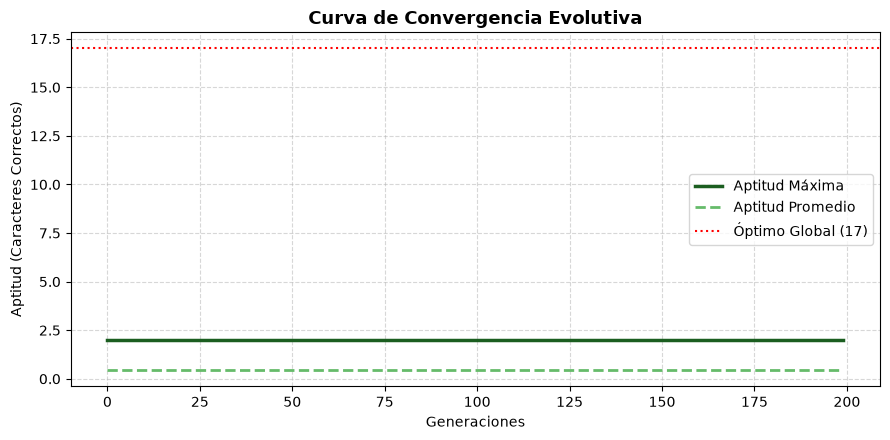

In [17]:
# 5. Ejecución y graficación 
max_h, avg_h = ejecutar_ag(FRASE_OBJETIVO) 
plt.figure(figsize=(9, 4.5)) 
plt.plot(max_h, label="Aptitud Máxima", color="#1B5E20", linewidth=2.5) 
plt.plot(avg_h, label="Aptitud Promedio", color="#66BB6A", linestyle="--", linewidth=2) 
plt.axhline(y=LONGITUD_FRASE, color="red", linestyle=":", label="Óptimo Global (17)") 
plt.title("Curva de Convergencia Evolutiva", fontsize=13, fontweight="bold") 
plt.xlabel("Generaciones") 
plt.ylabel("Aptitud (Caracteres Correctos)") 
plt.grid(True, linestyle="--", alpha=0.5) 
plt.legend() 
plt.tight_layout()
